# COT Reports (CFTC TFF) — positionnement, signaux et prévision, version desk

**Objectif** : transformer les rapports *Traders in Financial Futures* en un module de recherche **rigoureux** : features standard (COT index, z-scores, flux), **alignement temporel sans look-ahead**, tests prédictifs corrigés de l'autocorrélation (HAC), correction des **tests multiples**, backtests avec coûts et vol-targeting, prévision **walk-forward** contre un benchmark naïf, et robustesse statistique (Sharpe déflaté).

**Timing CFTC (crucial)** : positions mesurées le **mardi**, publiées le **vendredi 15h30 ET**. Utiliser la position du mardi pour trader dès le mardi = look-ahead de 3 jours. Ici : disponibilité = mardi + 3 j, entrée par défaut à la clôture du **lundi** (`EXEC_LAG = 2`).

**Catégories TFF** : *Dealers* (banques, contrepartie structurelle), *Asset Managers* (institutionnels, plutôt directionnels lents), *Leveraged Funds* (hedge funds / CTA, momentum et carry), *Other Reportables*.

In [1]:
import os, sys, json, warnings
warnings.filterwarnings("ignore")
sys.path.insert(0, os.getcwd())
import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns
from scipy import stats
from statsmodels.stats.multitest import multipletests
from quantdesk import cot
from quantdesk.style import apply_terminal_style, AMBER, CYAN, GREEN, RED, GREY, VIOLET
apply_terminal_style()
pd.options.display.float_format = "{:,.4f}".format

MARKETS    = ["EUR", "GBP", "JPY", "CHF", "AUD", "CAD", "NZD"]   # futures CME FX
START_YEAR = 2010
HORIZONS   = [1, 4, 13]         # semaines
EXEC_LAG   = 2                  # 1 = clôture du vendredi de publication, 2 = clôture du lundi
COST_BPS   = 1.5                # coût par unité de turnover (spot/futures FX liquides)
TARGET_VOL = 0.10               # vol cible annualisée par marché
NTRIALS    = 20                 # nombre de variantes/paramètres explorés (sert au Sharpe déflaté)

px, tabs, meta = cot.get_cot_universe(MARKETS, START_YEAR)
print(f"Source : {meta['source'].upper()} | prix {px.index[0].date()} → {px.index[-1].date()} | {len(tabs[MARKETS[0]])} rapports hebdo par marché")
if meta["source"] == "synthetic":
    print("⚠️  DONNÉES SYNTHÉTIQUES sans aucune prédictibilité injectée (edge = 0) : le résultat honnête attendu est « rien de significatif ». "
          "Avec accès Internet, get_cot_universe télécharge CFTC + prix spot (JPY/CAD/CHF/MXN inversés pour coïncider avec la cotation des futures).")
display(tabs["EUR"].tail(3))

Selected: traders_in_financial_futures_fut


Source : SYNTHETIC | prix 2009-10-12 → 2026-09-18 | 884 rapports hebdo par marché
⚠️  DONNÉES SYNTHÉTIQUES sans aucune prédictibilité injectée (edge = 0) : le résultat honnête attendu est « rien de significatif ». Avec accès Internet, get_cot_universe télécharge CFTC + prix spot (JPY/CAD/CHF/MXN inversés pour coïncider avec la cotation des futures).


,oi,lf_long,lf_short,dealer_long,dealer_short,am_long,am_short,oth_long,oth_short
2026-09-01,"224,790.1022","40,042.3038","58,865.3412","81,916.0416","66,445.4259","63,641.2689","57,745.3863","22,479.0102","22,479.0102"
2026-09-08,"213,614.8926","36,019.8317","57,970.7211","76,964.4989","64,021.3302","59,904.8209","55,447.2211","21,361.4893","21,361.4893"
2026-09-15,"215,625.5590","33,788.0825","61,087.1635","78,878.4521","63,434.4168","60,077.7069","56,360.0950","21,562.5559","21,562.5559"


## 1. Features de positionnement

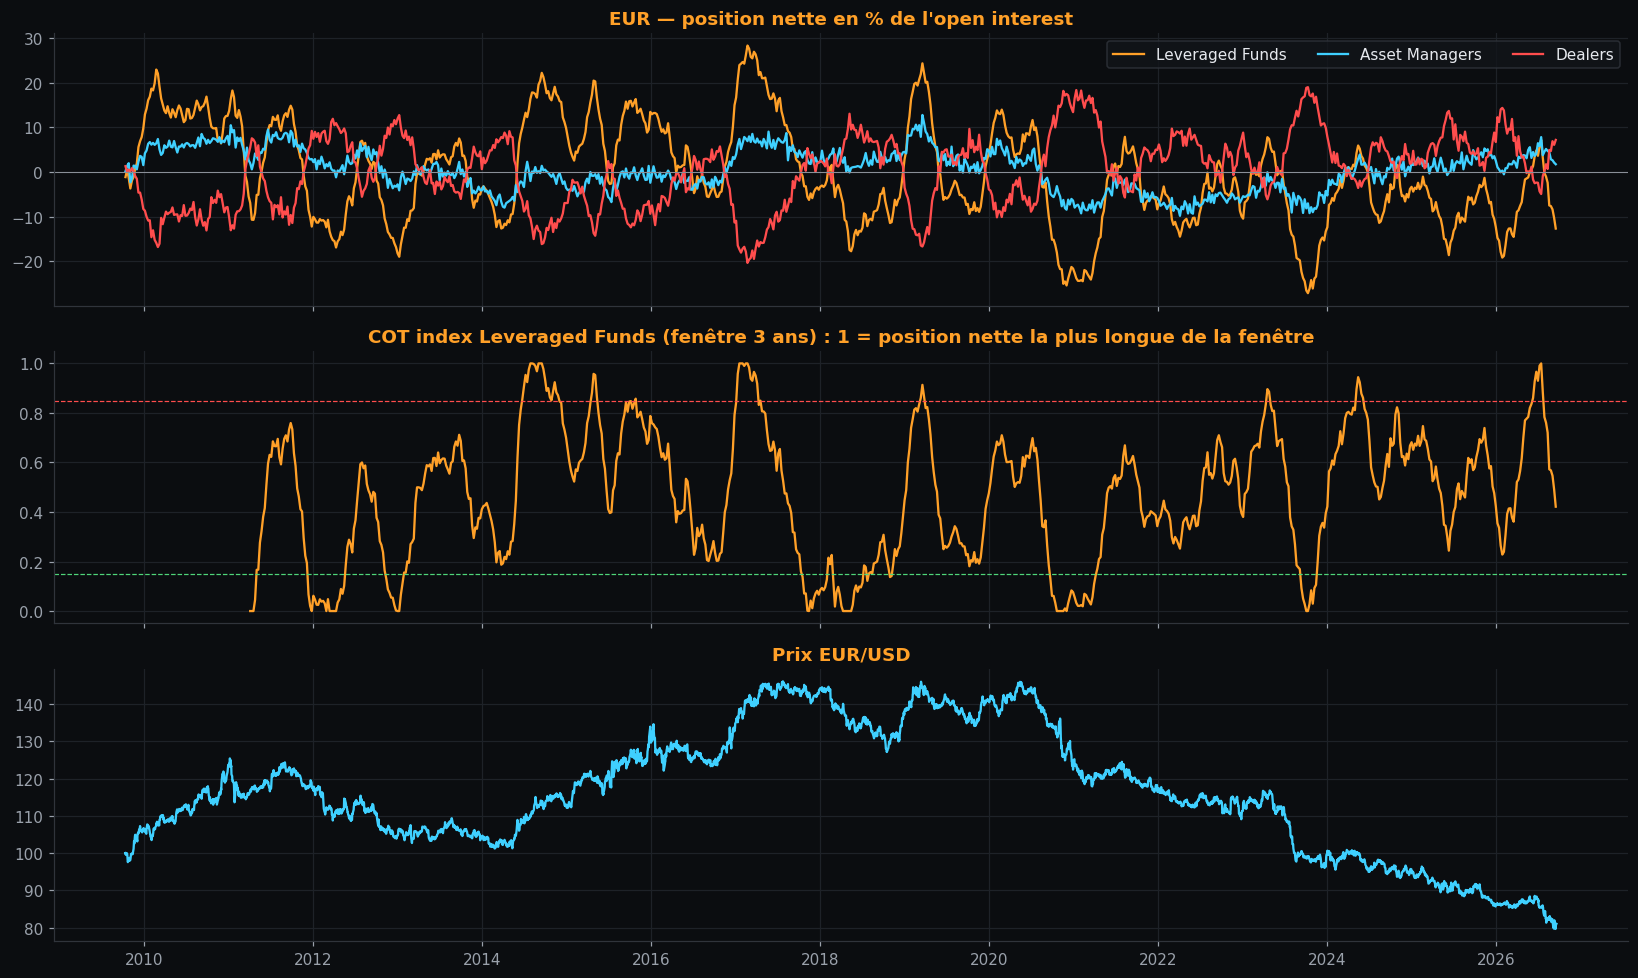

In [2]:
feats = {m: cot.build_features(tabs[m]) for m in MARKETS}
f = feats["EUR"]
fig, ax = plt.subplots(3, 1, figsize=(15, 9), sharex=True)
ax[0].plot(f["net_lf"], color=AMBER, label="Leveraged Funds"); ax[0].plot(f["net_am"], color=CYAN, label="Asset Managers")
ax[0].plot(f["net_dealer"], color=RED, label="Dealers"); ax[0].axhline(0, color=GREY, lw=.7); ax[0].legend(ncol=3)
ax[0].set_title("EUR — position nette en % de l'open interest")
ax[1].plot(f["idx_lf"], color=AMBER); ax[1].axhline(.85, color=RED, ls="--", lw=.8); ax[1].axhline(.15, color=GREEN, ls="--", lw=.8)
ax[1].set_title("COT index Leveraged Funds (fenêtre 3 ans) : 1 = position nette la plus longue de la fenêtre")
ax[2].plot(px["EUR"], color=CYAN); ax[2].set_title("Prix EUR/USD")
plt.tight_layout(); plt.show()

* **COT index** $=\dfrac{x_t-\min_N x}{\max_N x-\min_N x}$ : position relative dans sa propre histoire ; toutes les fenêtres sont **trailing** (jamais de min/max sur l'échantillon complet, qui contiendrait le futur).
* **Z-score** sur 3 ans glissants, **flux** (Δ 4 / 13 semaines), **Net_COT** = net LF − net Dealers (définition du notebook d'origine, conservée), **divergence** LF vs Asset Managers.
* On travaille en **% de l'OI** : les contrats et l'OI dérivent avec le temps, les niveaux bruts ne sont pas comparables.

## 2. Les positions prédisent-elles les rendements ? (avec la bonne statistique)

* Rendement forward mesuré **entre l'entrée réelle** (publication + `EXEC_LAG`) et la fin de l'horizon.
* Les rendements forward à 4 ou 13 semaines **se chevauchent** entre observations hebdomadaires, et les positions sont très persistantes : les erreurs standard OLS sont fausses. On utilise **Newey-West/HAC** avec au moins 13 retards (calibré par simulation sous H0 pour garder un test de taille ≈ 5 %).
* On teste 7 marchés × 3 horizons × 7 features = **147 hypothèses** : à 5 %, ~7 « découvertes » sortent par pur hasard. Correction de **Holm** (FWER) et **Benjamini-Hochberg** (FDR). Ces tests sont fortement corrélés (features quasi redondantes, mêmes marchés, horizons emboîtés) : le nombre de faux positifs est **sur-dispersé** par rapport au « 5 % × N » indépendant, ce qui renforce la nécessité de la correction.

,nombre
Tests,147.0000
significatifs à 5 % (brut),16.0000
attendus par hasard,7.4000
après Holm (FWER 5 %),1.0000
après Benjamini-Hochberg (FDR 5 %),5.0000


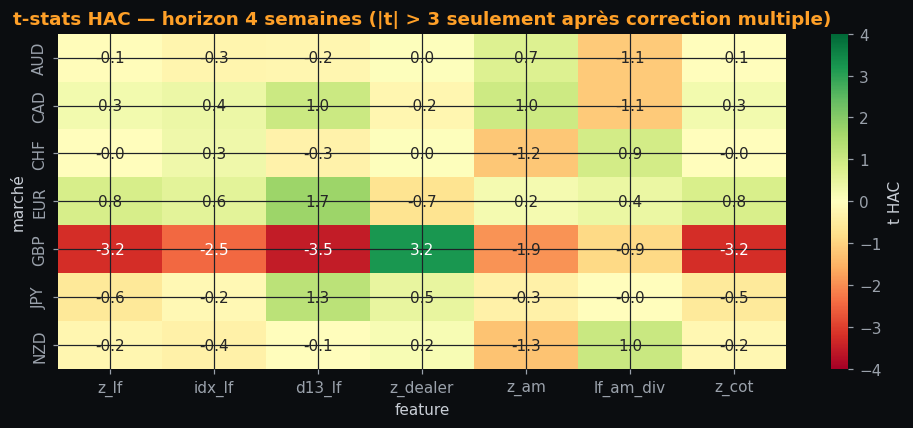

In [3]:
FEATS = {"z_lf": "Z LF", "idx_lf": "Index LF", "d13_lf": "Δ13s LF", "z_dealer": "Z Dealers",
         "z_am": "Z Asset Mgr", "lf_am_div": "Div LF−AM", "z_cot": "Z Net_COT"}
fwd = {h: {m: cot.forward_returns(px[m], feats[m].index, h, EXEC_LAG) for m in MARKETS} for h in HORIZONS}
rows = []
for m in MARKETS:
    for h in HORIZONS:
        for k in FEATS:
            r = cot.hac_regression(feats[m][k], fwd[h][m], h); ic = cot.rank_ic(feats[m][k], fwd[h][m], h)
            rows.append({"marché": m, "h": h, "feature": k, "n": r.get("n"), "beta/σ": r.get("beta_par_sigma"),
                         "t_HAC": r.get("t_HAC"), "p": r.get("p"), "IC": ic.get("IC")})
res = pd.DataFrame(rows).dropna(subset=["p"])
res["p_Holm"] = multipletests(res["p"], method="holm")[1]
res["p_BH"] = multipletests(res["p"], method="fdr_bh")[1]
summary = pd.Series({"Tests": len(res), "significatifs à 5 % (brut)": int((res["p"] < .05).sum()),
                     "attendus par hasard": round(len(res) * .05, 1), "après Holm (FWER 5 %)": int((res["p_Holm"] < .05).sum()),
                     "après Benjamini-Hochberg (FDR 5 %)": int((res["p_BH"] < .05).sum())})
display(summary.to_frame("nombre"))
piv = res[res["h"] == 4].pivot(index="marché", columns="feature", values="t_HAC")[list(FEATS)]
plt.figure(figsize=(9, 4)); sns.heatmap(piv, annot=True, fmt=".1f", cmap="RdYlGn", center=0, vmin=-4, vmax=4, cbar_kws={"label": "t HAC"})
plt.title("t-stats HAC — horizon 4 semaines (|t| > 3 seulement après correction multiple)"); plt.tight_layout(); plt.show()

h,1,4,13
IC de rang moyen (marchés),,,
z_lf,-0.0137,-0.0178,-0.0294
idx_lf,-0.0117,-0.0172,-0.0292
d13_lf,-0.0001,0.0047,0.0106
z_dealer,0.0136,0.0176,0.0298
z_am,-0.0265,-0.0251,-0.0388
lf_am_div,0.0131,-0.0016,-0.0117
z_cot,-0.0138,-0.0179,-0.0296


,mean,std,count,hit_rate_>0
quintile de Z LF (1 = le plus vendeur),,,,
1,0.0627,1.0173,1125,0.5049
2,-0.0634,0.9263,1124,0.4475
3,0.0724,0.9821,1124,0.5240
4,0.0675,1.0170,1124,0.5098
5,-0.0164,1.0944,1124,0.4867


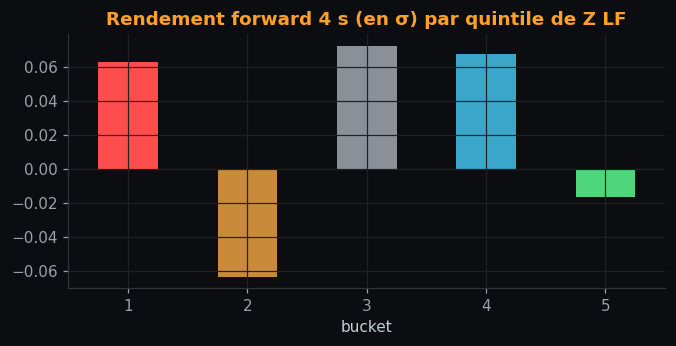

In [4]:
# IC moyen par feature/horizon + quintiles poolés du Z LF à 4 semaines
display(res.pivot_table(index="feature", columns="h", values="IC", aggfunc="mean").loc[list(FEATS)].rename_axis("IC de rang moyen (marchés)"))
pool_x, pool_y = [], []
for m in MARKETS:
    y = fwd[4][m]; pool_x.append(feats[m]["z_lf"]); pool_y.append(y / y.std())
bx = cot.bucket_returns(pd.concat(pool_x), pd.concat(pool_y), 5)
display(bx.rename_axis("quintile de Z LF (1 = le plus vendeur)"))
ax = bx["mean"].plot.bar(color=[RED, "#c98b3a", GREY, "#3aa6c9", GREEN], figsize=(7, 3)); ax.set_title("Rendement forward 4 s (en σ) par quintile de Z LF"); plt.xticks(rotation=0); plt.show()

**Lecture** : un signal exploitable se traduit par (i) des |t| élevés **qui survivent** à Holm/BH, (ii) un même signe d'IC sur la plupart des marchés, (iii) une relation monotone sur les quintiles. Un unique |t| > 2 parmi 147 tests n'est pas une découverte.

## 3. Backtests réalistes

* Position(t) = signal (info ≤ t − `EXEC_LAG`) × vol cible / vol EWMA (décalée d'un jour), plafond de levier ×3.
* Coûts = `COST_BPS` × turnover. Le portefeuille time-series est la moyenne des marchés ; le cross-section est **dollar-neutre** (long tercile haut / short tercile bas).
* Chaque variante testée **augmente le nombre d'essais** : on reporte le **Sharpe déflaté** (DSR, Bailey & López de Prado) qui corrige la sélection du meilleur essai, avec `NTRIALS` = nombre d'idées/paramètres réellement essayés.

In [5]:
VARIANTS = {
    "LF extrêmes (contrarian)":       lambda f: cot.sig_extreme(f["idx_lf"], .85, .15, True),
    "LF z-score (contrarian)":        lambda f: cot.sig_zscore(f["z_lf"], contrarian=True),
    "LF z-score (suiveur)":           lambda f: cot.sig_zscore(f["z_lf"], contrarian=False),
    "LF Δ13s (suiveur)":              lambda f: np.sign(f["d13_lf"]).fillna(0),
    "Dealers z-score (suiveur)":      lambda f: cot.sig_zscore(f["z_dealer"], contrarian=False),
    "Divergence LF−AM (contrarian)":  lambda f: cot.sig_zscore(f["lf_am_div"], contrarian=True),
}
bt_ret, bt_gross = {}, {}
for name, fn in VARIANTS.items():
    parts = [cot.backtest_time_series(px[m], fn(feats[m]), TARGET_VOL, 3.0, COST_BPS, EXEC_LAG) for m in MARKETS]
    bt_ret[name]   = pd.concat([p["ret"] for p in parts], axis=1).mean(axis=1)
    bt_gross[name] = pd.concat([p["gross"] for p in parts], axis=1).mean(axis=1)
S = pd.DataFrame({m: -feats[m]["z_lf"] for m in MARKETS}).dropna()           # contrarian cross-section
cs = cot.backtest_cross_section(px, S, TARGET_VOL, COST_BPS, EXEC_LAG)
bt_ret["Cross-section LF (contrarian)"], bt_gross["Cross-section LF (contrarian)"] = cs["ret"], cs["gross"]

def maxdd(r): w = (1 + r.fillna(0)).cumprod(); return (w / w.cummax() - 1).min()
rows = {}
for k, r in bt_ret.items():
    r = r[r != 0].dropna() if (r != 0).sum() > 100 else r.dropna()
    ci = cot.stationary_bootstrap_sharpe(r, n_boot=1000)
    d = cot.deflated_sharpe(r, NTRIALS)
    rows[k] = {"Sharpe net": cot.sharpe(r), "Sharpe brut": cot.sharpe(bt_gross[k].loc[r.index]), "IC95 bas": ci[0], "IC95 haut": ci[2],
               "Vol": r.std()*np.sqrt(252), "MaxDD": maxdd(r), "PSR(0)": d["PSR(0)"], "DSR": d["DSR"]}
perf = pd.DataFrame(rows).T
display(perf)

,Sharpe net,Sharpe brut,IC95 bas,IC95 haut,Vol,MaxDD,PSR(0),DSR
LF extrêmes (contrarian),0.3447,0.3951,-0.1596,0.8750,0.0209,-0.0653,0.8995,0.2667
LF z-score (contrarian),0.0580,0.1218,-0.4338,0.5730,0.0210,-0.0772,0.5918,0.0476
LF z-score (suiveur),-0.1857,-0.1218,-0.7007,0.2976,0.0210,-0.1184,0.2290,0.0041
LF Δ13s (suiveur),-0.0886,-0.0100,-0.5341,0.3597,0.0396,-0.1970,0.3564,0.0117
Dealers z-score (suiveur),0.0249,0.1050,-0.4631,0.5285,0.0210,-0.0777,0.5397,0.0359
Divergence LF−AM (contrarian),-0.3184,-0.2183,-0.7960,0.1500,0.0229,-0.1634,0.1017,0.0008
Cross-section LF (contrarian),-0.1346,-0.0996,-0.6417,0.3501,0.1050,-0.4540,0.2951,0.0073


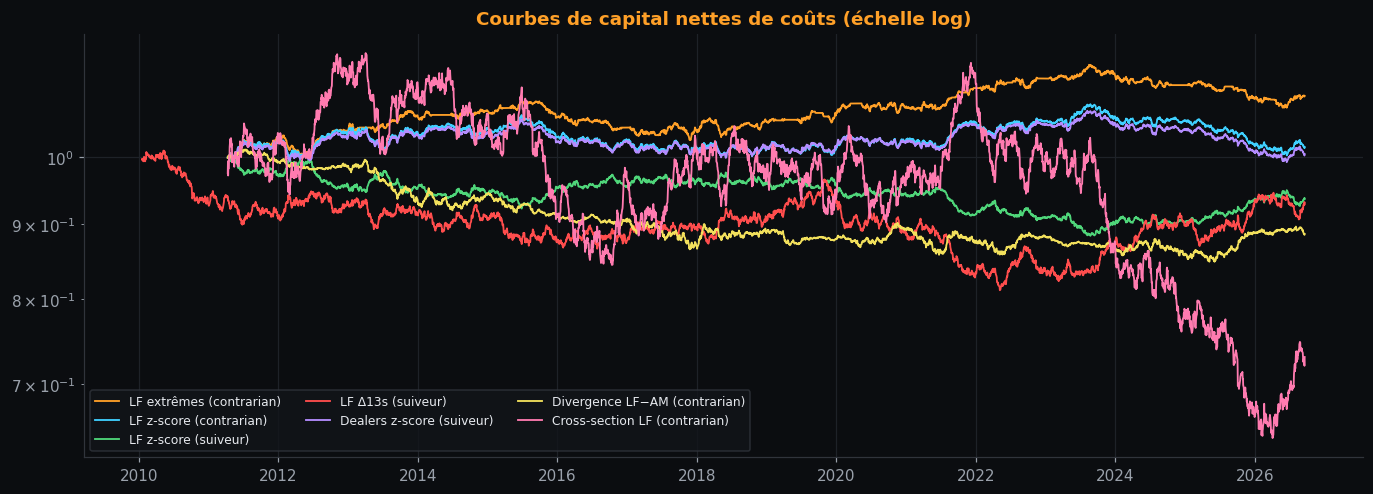

In [6]:
fig, ax = plt.subplots(figsize=(15, 5))
for k, r in bt_ret.items():
    r = r.loc[r.ne(0).idxmax():] if r.ne(0).any() else r
    ax.plot((1 + r.fillna(0)).cumprod(), lw=1.2, label=k)
ax.set_yscale("log"); ax.legend(ncol=3, fontsize=8); ax.set_title("Courbes de capital nettes de coûts (échelle log)"); plt.show()

**Comment lire le tableau** : un **IC95 du Sharpe** qui contient 0 = pas de preuve d'edge ; **PSR(0)** = probabilité que le vrai Sharpe soit > 0 ; **DSR** = même chose après correction du nombre d'essais (il faut typiquement > 0,95). L'écart *Sharpe brut − net* mesure la consommation par les coûts.

## 4. Prévision walk-forward (remplace le LSTM récursif)

Pourquoi le LSTM d'origine ne pouvait pas fonctionner : (i) la cible était le **niveau** de Net_COT (autocorrélation ≈ 1 : « prédire » = recopier la dernière valeur) ; (ii) ~370 échantillons pour 200+200 neurones et 200 epochs, sans validation ni early-stopping ; (iii) prévision **récursive** sur 100 pas (l'erreur s'accumule) ; (iv) ni normalisation ni benchmark naïf ; (v) cible non tradable.

Ici : cible = **rendement forward 4 s normalisé par sa vol**, panel des 7 marchés, entraînement *expanding* **purgé** (embargo 4 s car les cibles se chevauchent), réestimation tous les 13 s, modèles **régularisés** (Ridge, gradient boosting peu profond), et comparaison au benchmark « moyenne historique » par le **R² hors-échantillon de Campbell-Thompson** et le test de **Diebold-Mariano**.

In [7]:
Xs, ys = {}, {}
for m in MARKETS:
    f = feats[m]
    wk = px[m].reindex(f.index, method="ffill"); wret = wk.pct_change()
    X = f[["z_lf", "idx_lf", "d4_lf", "d13_lf", "z_dealer", "z_am", "lf_am_div", "z_cot", "gross_lf", "oi_chg_13w"]].copy()
    X["mom13"] = wk.pct_change(13) / (wret.rolling(26).std() * np.sqrt(13))
    vol4 = wret.rolling(26).std() * 2
    Xs[m], ys[m] = X, fwd[4][m] / vol4
X = pd.concat(Xs, names=["marché", "date"]).swaplevel().sort_index()
y = pd.concat(ys, names=["marché", "date"]).swaplevel().sort_index()
oos = {}
for model in ("ridge", "gbm"):
    oos[model] = cot.walk_forward_forecast(X, y, model, min_train=260, refit_every=13, embargo=4, alpha=200.0)
rows = {}
for k, o in oos.items():
    da = cot.directional_accuracy(o["y"], o["pred"]); dm = cot.diebold_mariano(o["y"], o["pred"], o["bench"], 4)
    ic_t = o.groupby(level=0).apply(lambda g: stats.spearmanr(g["pred"], g["y"])[0] if len(g) > 3 else np.nan).dropna()
    rows[k] = {"N OOS": len(o), "R² OOS (vs moyenne)": cot.oos_r2(o["y"], o["pred"], o["bench"]), "DM stat": dm["DM"], "p(DM)": dm["p"],
               "Précision directionnelle": da["accuracy"], "p(binomiale vs 50%)": da["p_binomial_vs_50%"],
               "IC coupe transv. moyen": ic_t.mean(), "t(IC)": ic_t.mean() / ic_t.std() * np.sqrt(len(ic_t))}
display(pd.DataFrame(rows).T)

,N OOS,R² OOS (vs moyenne),DM stat,p(DM),Précision directionnelle,p(binomiale vs 50%),IC coupe transv. moyen,t(IC)
ridge,"3,801.0000",-0.0110,4.2366,0.0000,0.4880,0.1443,-0.0228,-1.2743
gbm,"3,801.0000",-0.0468,8.4292,0.0000,0.4867,0.1048,-0.0332,-1.8364


Ridge walk-forward → Sharpe net = -0.73 | PSR(0) = 0.01 | DSR = 0.00


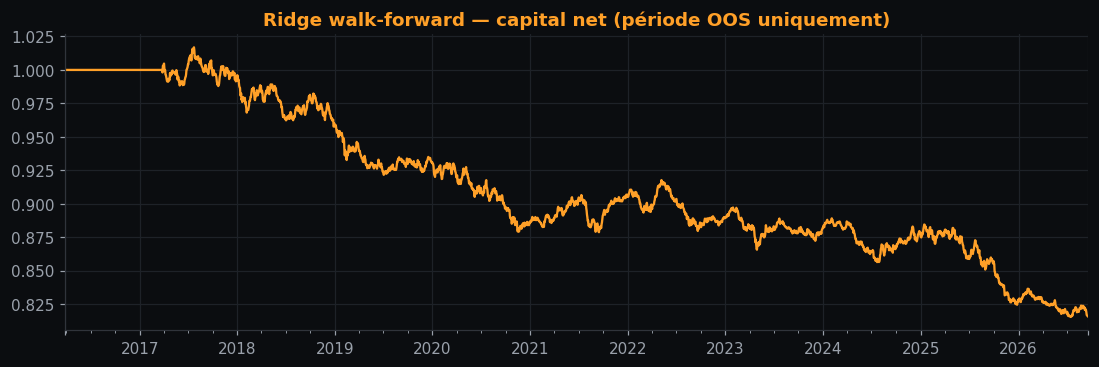

In [8]:
# Stratégie issue des prévisions Ridge (uniquement sur la période hors-échantillon)
o = oos["ridge"]["pred"].unstack("marché")
sig = {m: np.clip(o[m] / o[m].expanding(52).std(), -1, 1).fillna(0) for m in MARKETS}
parts = [cot.backtest_time_series(px[m], sig[m], TARGET_VOL, 3.0, COST_BPS, EXEC_LAG)["ret"] for m in MARKETS]
ml = pd.concat(parts, axis=1).mean(axis=1); ml = ml.loc[o.index[0]:]
d = cot.deflated_sharpe(ml[ml != 0], NTRIALS + 4)
print(f"Ridge walk-forward → Sharpe net = {cot.sharpe(ml):.2f} | PSR(0) = {d['PSR(0)']:.2f} | DSR = {d['DSR']:.2f}")
plt.figure(figsize=(12, 3.5)); (1 + ml).cumprod().plot(color=AMBER); plt.title("Ridge walk-forward — capital net (période OOS uniquement)"); plt.show()

**Critères de validation avant d'accepter un modèle** : R² OOS > 0 *et* Diebold-Mariano **négatif** et significatif (stat > 0 significative = le benchmark bat le modèle) *et* IC de coupe transversale stable *et* DSR élevé. Un R² OOS ≤ 0 signifie que le modèle fait pire que la simple moyenne historique — le cas le plus fréquent en finance.

## 5. Test de validation du pipeline (taille et puissance)

Un pipeline de recherche doit prouver deux choses : ne **rien trouver** quand il n'y a rien (taille), et **détecter** un effet quand il existe (puissance). On génère des marchés synthétiques où l'on **injecte** un contrarian de force connue `edge` (0 = aucun) et on relance les tests.

In [9]:
def synth_universe(edge, seed):
    p, t = {}, {}
    for i, m in enumerate(MARKETS):
        p[m], t[m] = cot.synthetic_cot_market(700, edge=edge, seed=seed + i, ann_vol=0.08 + 0.01 * (i % 4))
    return pd.DataFrame(p), t

rows = {}
for edge in (0.0, 0.15, 0.30):
    runs = []
    for seed in range(300, 300 + 10 * len(MARKETS), len(MARKETS)):          # 10 univers indépendants par niveau d'edge
        pxs, ts = synth_universe(edge, seed=seed)
        fs = {m: cot.build_features(ts[m]) for m in MARKETS}
        fw = {m: cot.forward_returns(pxs[m], fs[m].index, 4, EXEC_LAG) for m in MARKETS}
        tt = np.mean([cot.hac_regression(fs[m]["z_lf"], fw[m], 4)["t_HAC"] for m in MARKETS])
        ic = np.mean([cot.rank_ic(fs[m]["z_lf"], fw[m], 4)["IC"] for m in MARKETS])
        Sx = pd.DataFrame({m: -fs[m]["z_lf"] for m in MARKETS}).dropna()
        r = cot.backtest_cross_section(pxs, Sx, TARGET_VOL, COST_BPS, EXEC_LAG)["ret"]; r = r[r != 0]
        runs.append({"t": tt, "IC": ic, "SR": cot.sharpe(r), "DSR": cot.deflated_sharpe(r, NTRIALS)["DSR"]})
    d = pd.DataFrame(runs)
    rows[f"edge = {edge}"] = {"t HAC moyen (Z LF, 4 s)": d["t"].mean(), "IC moyen": d["IC"].mean(), "Sharpe net moyen": d["SR"].mean(),
                              "σ du Sharpe entre univers": d["SR"].std(), "% univers avec DSR > 0,95": (d["DSR"] > .95).mean() * 100}
display(pd.DataFrame(rows).T)

,"t HAC moyen (Z LF, 4 s)",IC moyen,Sharpe net moyen,σ du Sharpe entre univers,"% univers avec DSR > 0,95"
edge = 0.0,0.0868,0.0043,-0.1010,0.3434,0.0000
edge = 0.15,-3.0986,-0.2215,1.7314,0.2399,100.0000
edge = 0.3,-5.9390,-0.3821,3.4491,0.4529,100.0000


**Attendu** : à `edge = 0` le t moyen ≈ 0, le Sharpe moyen ≈ 0 et la part d'univers avec DSR > 0,95 reste faible (taux de fausses découvertes, à comparer à `NTRIALS`) ; à `edge > 0` le t devient significativement **négatif** (contrarian), le Sharpe positif et le DSR proche de 1. C'est la garantie que le code n'invente ni ne rate d'effet de cette taille.

## 6. Export pour le terminal

In [10]:
snap = {"meta": {"source": meta["source"], "exec_lag": EXEC_LAG, "note": "position mardi, publication vendredi"}, "markets": {}}
for m in MARKETS:
    f = feats[m].iloc[-1]; last = feats[m].index[-1]
    snap["markets"][m] = {
        "report_date": str(last.date()), "available_from": str((last + pd.Timedelta(days=3)).date()),
        "net_pct_oi": {"lev_funds": float(f["net_lf"]), "asset_mgr": float(f["net_am"]), "dealers": float(f["net_dealer"])},
        "cot_index_lf_3y": float(f["idx_lf"]), "z_lf_3y": float(f["z_lf"]), "d4w_lf": float(f["d4_lf"]), "d13w_lf": float(f["d13_lf"]),
        "flags": {"crowded_long": bool(f["idx_lf"] >= .85), "crowded_short": bool(f["idx_lf"] <= .15)}}
with open("cot_snapshot.json", "w") as fh: json.dump(snap, fh, indent=2, default=float)
display(pd.DataFrame({m: {"date": v["report_date"], "LF % OI": v["net_pct_oi"]["lev_funds"], "index LF": v["cot_index_lf_3y"], "Z LF": v["z_lf_3y"]} for m, v in snap["markets"].items()}).T)

,date,LF % OI,index LF,Z LF
EUR,2026-09-15,-12.6604,0.4214,-0.7558
GBP,2026-09-15,-3.6794,0.0327,-2.1722
JPY,2026-09-15,-2.3371,0.2939,-0.6285
CHF,2026-09-15,10.9833,0.6631,0.9071
AUD,2026-09-15,-1.5070,0.3652,-0.2554
CAD,2026-09-15,-12.0578,0.3200,-0.7560
NZD,2026-09-15,11.0196,0.7843,1.3964


## 7. Ce qui a été corrigé par rapport à la version d'origine

| # | Problème dans le notebook d'origine | Correction |
|---|---|---|
| 1 | Dépendance à **MetaTrader** (`mt5` jamais importé ⇒ `NameError`), `!pip install` en ligne, code mort (M15/H1…) | Prix via yfinance avec cache, module `quantdesk.cot` propre |
| 2 | `np.float` (supprimé de NumPy ≥ 1.24) | Types natifs |
| 3 | `multiple_data_preprocessing` : colonnes recopiées (`data[:,3] = roll(data[:,1])`) ⇒ features dupliquées et fausses | Features construites explicitement, toutes *trailing* |
| 4 | LSTM sur le **niveau** de Net_COT, 100 lags, 200 neurones, 200 epochs, prévision récursive, sans benchmark | Cible = rendement forward normalisé, walk-forward purgé, Ridge/GBM, R² OOS + Diebold-Mariano |
| 5 | Aucun délai de publication (mardi → vendredi) | Alignement explicite `release_lag` + `EXEC_LAG` |
| 6 | `'BRITISH POUND STERLING - …'` (nom obsolète) et noms exacts codés en dur | Regex robustes par marché |
| 7 | Précision de signe brute sans test de significativité ; `model_bias` divisait par zéro ; `compute_diff` bouclait sur l'indice −1 | Tests binomial, HAC, IC, DM |
| 8 | Volatilité = écart-type des **prix** (pas des rendements) | Vol EWMA des rendements, vol-targeting |
| 9 | Pas de coûts, de correction de tests multiples, ni de mesure de robustesse | Coûts, Holm/BH, bootstrap stationnaire, PSR/DSR, test taille/puissance |

**Limites** : positions *futures-only* (l'option-adjusted « futures and options combined » existe aussi) ; série continue spot ≠ futures (carry/roll non modélisé) ; échantillon hebdomadaire court (≈ 700 points par marché) donc peu de puissance statistique ; les jours fériés retardant la publication ne sont pas modélisés.